# ACML Assignment 1: Backpropagation

**Authors:** Thai Binh Nguyen and Ege Deniz

An 8–3–8 autoencoder trained to reconstruct eight one-hot patterns.

## 1. Dataset

Each row is one example; the target equals the input.

In [1]:
import numpy as np

X = np.eye(8)
Y = X.copy()

print("Input patterns (targets are identical):")
print(X.astype(int))

Input patterns (targets are identical):
[[1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 1]]


## 2. Architecture and initialization

8 inputs → 3 hidden units → 8 outputs, with biases: **59 parameters**.

`W1: (8,3)`, `b1: (3,)`, `W2: (3,8)`, `b2: (8,)`.

Baseline: uniform weights in `[-0.1, 0.1]`, zero biases, seed 0.

In [ ]:
input_size = 8
hidden_size = 3
output_size = 8
rng = np.random.default_rng(seed=0)             
initialization_range = 0.1
W1 = rng.uniform(
    -initialization_range,
    initialization_range,
    size=(input_size, hidden_size),
)
b1 = np.zeros(hidden_size)

W2 = rng.uniform(
    -initialization_range,
    initialization_range,
    size=(hidden_size, output_size),
)
b2 = np.zeros(output_size)

## 3. Forward propagation

$$\sigma(z)=\frac{1}{1+e^{-z}}$$

$$H=\sigma(XW_1+b_1),\qquad \hat Y=\sigma(HW_2+b_2)$$

In [ ]:
def sigmoid(z):                                        
    with np.errstate(over="ignore"):
        return 1.0 / (1.0 + np.exp(-z))

def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    H = sigmoid(Z1)

    Z2 = H @ W2 + b2
    Y_pred = sigmoid(Z2)

    return H, Y_pred

## 4. Reconstruction loss

$$L=\frac{1}{2m}\sum_{i=1}^{m}\sum_{j=1}^{8}(\hat Y_{ij}-Y_{ij})^2$$

Sum over outputs; average over examples.

In [4]:
def reconstruction_loss(Y, Y_pred):
    m = Y.shape[0]
    return np.sum((Y_pred - Y) ** 2) / (2 * m)

## 5. Backpropagation

$$\sigma'(z)=\sigma(z)(1-\sigma(z))$$

$$D_2=(\hat Y-Y)\odot\hat Y\odot(1-\hat Y)/m$$

$$D_1=(D_2W_2^T)\odot H\odot(1-H)$$

Weight gradients: `X.T @ D1`, `H.T @ D2`. Bias gradients: column sums of deltas.

In [ ]:
def backward(X, Y, H, Y_pred, W2):
    m = X.shape[0]
    D2 = (Y_pred - Y) * Y_pred * (1 - Y_pred) / m
    D1 = (D2 @ W2.T) * H * (1 - H)
    dW2 = H.T @ D2
    db2 = np.sum(D2, axis=0)
    dW1 = X.T @ D1
    db1 = np.sum(D1, axis=0)
    return {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2,
    }
parameters = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

## 6. Gradient check

Central finite differences for all 59 parameters, with `epsilon = 1e-5`.
Supplementary check from *Backprop Help*, Section 2.3.

In [ ]:
def check_gradients(X_check, Y_check, parameters, epsilon=1e-5):
    H_check, prediction_check = forward(
        X_check,
        parameters["W1"],
        parameters["b1"],
        parameters["W2"],
        parameters["b2"],
    )
    analytical = backward(
        X_check, Y_check, H_check, prediction_check, parameters["W2"]
    )

    def current_loss():
        _, prediction = forward(
            X_check,
            parameters["W1"],
            parameters["b1"],
            parameters["W2"],
            parameters["b2"],
        )
        return reconstruction_loss(Y_check, prediction)
    errors = {}

    for name, parameter in parameters.items():
        numerical = np.zeros_like(parameter)
        for index in np.ndindex(parameter.shape):
            original_value = parameter[index]
            try:
                parameter[index] = original_value + epsilon
                loss_plus = current_loss()

                parameter[index] = original_value - epsilon
                loss_minus = current_loss()
            finally:
                parameter[index] = original_value

            numerical[index] = (
                (loss_plus - loss_minus) / (2 * epsilon)
            )
        max_error = np.max(np.abs(numerical - analytical[name]))
        errors[name] = float(max_error)
    return errors

selected_rows = [0, 2, 5]
gradient_errors = check_gradients(X[selected_rows], Y[selected_rows], parameters)
max_gradient_error = max(gradient_errors.values())
assert max_gradient_error < 1e-7, "Gradient check failed."
print(f"Gradient check: PASS (59 parameters, max error {max_gradient_error:.2e})")

Gradient check: PASS (59 parameters, max error 1.67e-11)


## 7. Training

Full-batch gradient descent: `parameter -= learning_rate * gradient`.

Stop at maximum absolute error ≤ 0.10, or 20,000 epochs.
One epoch = one update = eight pattern presentations.

In [ ]:
import time

def train(X, Y, initial_parameters, learning_rate=3.0,
          max_epochs=20000, tolerance=0.10):

    trained_parameters = {
        name: value.copy()
        for name, value in initial_parameters.items()
    }

    def predict():
        return forward(
            X,
            trained_parameters["W1"],
            trained_parameters["b1"],
            trained_parameters["W2"],
            trained_parameters["b2"],
        )

    H, prediction = predict()
    history = [reconstruction_loss(Y, prediction)]
    max_error = float(np.max(np.abs(prediction - Y)))
    epochs_completed = 0
    start_time = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        if max_error <= tolerance:
            break
        gradients = backward(
            X, Y, H, prediction, trained_parameters["W2"]
        )
        for name in trained_parameters:
            trained_parameters[name] -= (
                learning_rate * gradients[name]
            )
        H, prediction = predict()
        loss = reconstruction_loss(Y, prediction)
        max_error = float(np.max(np.abs(prediction - Y)))
        if not np.isfinite(loss):
            raise FloatingPointError("Training produced a non-finite loss.")
        history.append(loss)
        epochs_completed = epoch
    elapsed_time = time.perf_counter() - start_time
    result = {
        "success": max_error <= tolerance,
        "epochs": epochs_completed,
        "pattern_presentations": epochs_completed * X.shape[0],
        "seconds": elapsed_time,
        "final_loss": history[-1],
        "max_error": max_error,
    }
    return trained_parameters, np.array(history), result

trained_parameters, loss_history, training_result = train(
    X,
    Y,
    initial_parameters=parameters,
    learning_rate=3.0,
    max_epochs=20000,
    tolerance=0.10,
)

for name, value in training_result.items():
    if isinstance(value, float):
        print(f"{name}: {value:.6f}")
    else:
        print(f"{name}: {value}")

success: True
epochs: 3644
pattern_presentations: 29152
seconds: 0.188179
final_loss: 0.006506
max_error: 0.099990


## 8. Reconstruction

Binary outputs use threshold 0.5; the loss curve uses continuous predictions.

Reconstructed patterns:
[[1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 1]]
Correct: 8/8
Loss: 1.016208 → 0.006506


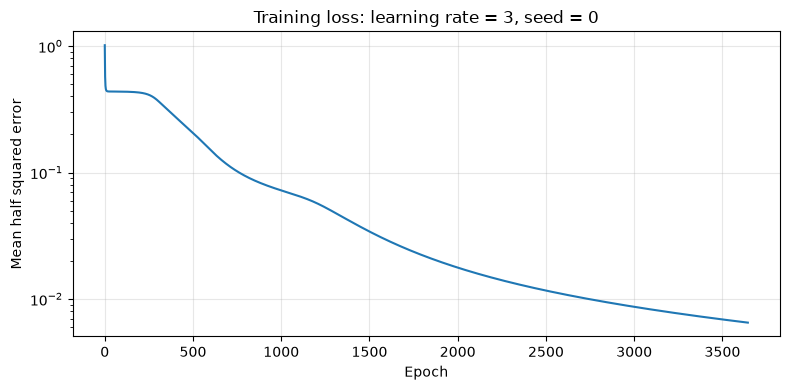

In [ ]:
import matplotlib.pyplot as plt

H_trained, Y_trained = forward(
    X, trained_parameters["W1"], trained_parameters["b1"],
    trained_parameters["W2"], trained_parameters["b2"],
)
Y_binary = (Y_trained >= 0.5).astype(int)
correct_patterns = np.all(Y_binary == Y, axis=1)
assert correct_patterns.all() and np.max(np.abs(Y_trained - Y)) <= 0.10
print("Reconstructed patterns:")
print(Y_binary)
print(f"Correct: {correct_patterns.sum()}/{len(X)}")
print(f"Loss: {loss_history[0]:.6f} → {loss_history[-1]:.6f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(len(loss_history)), loss_history)
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean half squared error")
ax.set_title("Training loss: learning rate = 3, seed = 0")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Baseline result

All **8/8 patterns** reconstructed after thresholding; tolerance reached in **3,644 epochs**.
Final loss: **0.006506**; maximum error: **0.099990**.

## 9. Experiments

- Rates `0.1, 1, 3, 10, 100`, with scale 1.
- Scales `0, 0.01, 1, 5`, with rate 3.
- Seeds 0–9; **80 runs** including failures.

Weights: uniform `[-0.1 × scale, 0.1 × scale]`; zero biases.
Scale 0 repeats the same initialization for every seed.

In [ ]:
def initialize_parameters(seed=0, scale=1.0):
    rng = np.random.default_rng(seed)
    weight_range = 0.1 * scale
    return {
        "W1": rng.uniform(
            -weight_range, weight_range, size=(8, 3)
        ),
        "b1": np.zeros(3),
        "W2": rng.uniform(
            -weight_range, weight_range, size=(3, 8)
        ),
        "b2": np.zeros(8),
    }

In [ ]:
import csv
from pathlib import Path
learning_rates = [0.1, 1.0, 3.0, 10.0, 100.0]
configurations = [(lr, 1.0) for lr in learning_rates]                 
configurations += [(3.0, scale) for scale in [0.0, 0.01, 5.0]]
experiment_results = []
experiment_curves = {}
for learning_rate, scale in configurations:
    for seed in range(10):
        initial_parameters = initialize_parameters(
            seed=seed,
            scale=scale,
        )
        _, history, result = train(
            X,
            Y,
            initial_parameters=initial_parameters,
            learning_rate=learning_rate,
            max_epochs=20000,
            tolerance=0.10,
        )
        row = {
            "learning_rate": learning_rate,
            "scale": scale,
            "seed": seed,
            **result,
        }
        experiment_results.append(row)

        if seed == 0:
            experiment_curves[(learning_rate, scale)] = history.copy()
results_directory = Path("results")
results_directory.mkdir(exist_ok=True)
csv_path = results_directory / "experiment_runs.csv"
with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(experiment_results[0].keys()),
    )
    writer.writeheader()
    writer.writerows(experiment_results)
print(f"\nCompleted {len(experiment_results)} runs.")


Completed 80 runs.


## 10. Experiment results

Epoch medians include successful runs only; time and loss medians include all runs.
Curves show seed 0.

In [ ]:
from IPython.display import display, Markdown
summary_rows = []
for learning_rate, scale in configurations:
    group = [
        row for row in experiment_results
        if row["learning_rate"] == learning_rate
        and row["scale"] == scale
    ]
    successful_runs = [row for row in group if row["success"]]
    median_epochs = (
        float(np.median([
            row["epochs"] for row in successful_runs
        ]))
        if successful_runs else None
    )
    summary_rows.append({
        "learning_rate": learning_rate,
        "scale": scale,
        "successes": len(successful_runs),
        "runs": len(group),
        "median_epochs_success": median_epochs,
        "median_seconds": float(np.median([
            row["seconds"] for row in group
        ])),
        "median_final_loss": float(np.median([
            row["final_loss"] for row in group
        ])),
    })
table_lines = [
    "| Learning rate | Scale | Success | Median epochs* | "
    "Median seconds** | Median final loss |",
    "|---|---|---|---|---|---|",
]
for row in summary_rows:
    epoch_text = (
        f'{row["median_epochs_success"]:,.1f}'
        if row["median_epochs_success"] is not None
        else "—"
    )
    table_lines.append(
        f'| {row["learning_rate"]:g} '
        f'| {row["scale"]:g} '
        f'| {row["successes"]}/{row["runs"]} '
        f'| {epoch_text} '
        f'| {row["median_seconds"]:.3f} '
        f'| {row["median_final_loss"]:.6f} |'
    )
display(Markdown("\n".join(table_lines)))

display(Markdown(
    "*\\* Successful runs only. "
    "\\*\\* All runs; unsuccessful runs reach the epoch limit.*"
))
summary_path = results_directory / "experiment_summary.csv"

with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(summary_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(summary_rows)

| Learning rate | Scale | Success | Median epochs* | Median seconds** | Median final loss |
|---|---|---|---|---|---|
| 0.1 | 1 | 0/10 | — | 0.952 | 0.163174 |
| 1 | 1 | 10/10 | 10,880.0 | 0.539 | 0.006096 |
| 3 | 1 | 10/10 | 3,552.5 | 0.177 | 0.006057 |
| 10 | 1 | 10/10 | 1,054.5 | 0.053 | 0.006188 |
| 100 | 1 | 0/10 | — | 0.962 | 0.468749 |
| 3 | 0 | 0/10 | — | 1.035 | 0.016545 |
| 3 | 0.01 | 10/10 | 4,557.5 | 0.226 | 0.006064 |
| 3 | 5 | 10/10 | 3,442.5 | 0.174 | 0.006494 |

*\* Successful runs only. \*\* All runs; unsuccessful runs reach the epoch limit.*

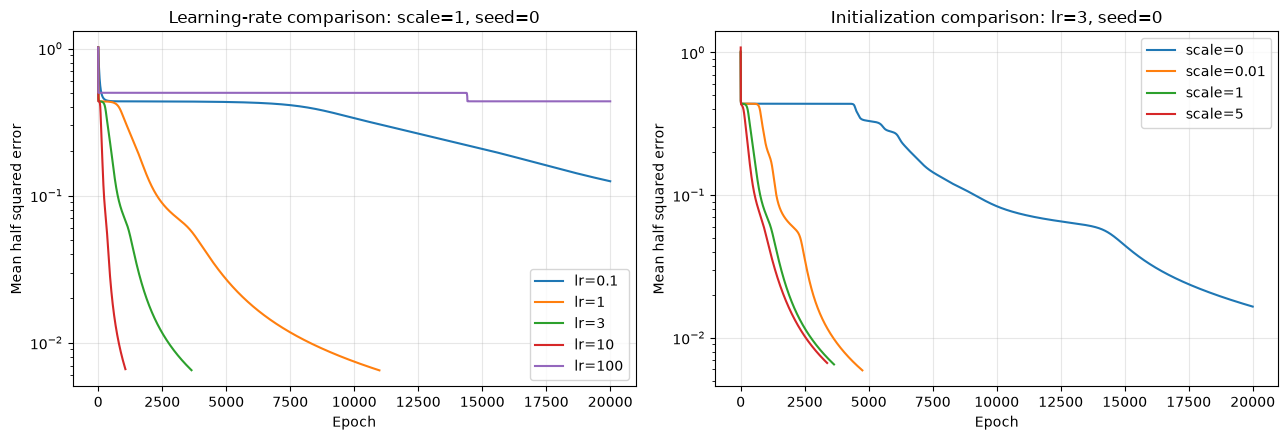

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for learning_rate in learning_rates:
    history = experiment_curves[(learning_rate, 1.0)]
    axes[0].plot(
        np.arange(len(history)),
        history,
        label=f"lr={learning_rate:g}",
    )
axes[0].set_title("Learning-rate comparison: scale=1, seed=0")

for scale in [0.0, 0.01, 1.0, 5.0]:
    history = experiment_curves[(3.0, scale)]

    axes[1].plot(
        np.arange(len(history)),
        history,
        label=f"scale={scale:g}",
    )
axes[1].set_title("Initialization comparison: lr=3, seed=0")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean half squared error")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
figure_path = results_directory / "experiment_learning_curves.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

### Learning rate

Rates 1, 3 and 10 succeed for all ten seeds. Rate 10 is fastest among tested rates
(median **1,054.5 epochs**). Rates 0.1 and 100 fail within the budget.

### Initialization

At rate 3, scales 0.01, 1 and 5 succeed; scale 0 fails.
Median epochs: **4,557.5**, **3,552.5**, **3,442.5**, respectively.
Ten successful seeds do not guarantee every initialization will converge.

## 11. Hidden representation

For one-hot input `i`: `Z1[i, :] = W1[i, :] + b1`.
The decoder uses continuous hidden activations, not thresholded codes.

In [13]:
W1_trained = trained_parameters["W1"]
b1_trained = trained_parameters["b1"]
W2_trained = trained_parameters["W2"]
b2_trained = trained_parameters["b2"]

H_trained, Y_trained = forward(X, W1_trained, b1_trained, W2_trained, b2_trained)
hidden_codes = (H_trained >= 0.5).astype(int)
unique_binary_codes = np.unique(hidden_codes, axis=0).shape[0]

print("Hidden codes:", ["".join(map(str, code)) for code in hidden_codes])
print("Distinct binary codes:", unique_binary_codes)
print("Output 7 weights:", np.round(W2_trained[:, 6], 3))
print(f"Output 7 bias: {b2_trained[6]:.3f}")

Hidden codes: ['000', '010', '110', '100', '101', '011', '010', '001']
Distinct binary codes: 7
Output 7 weights: [ -2.132   6.567 -11.176]
Output 7 bias: -2.978


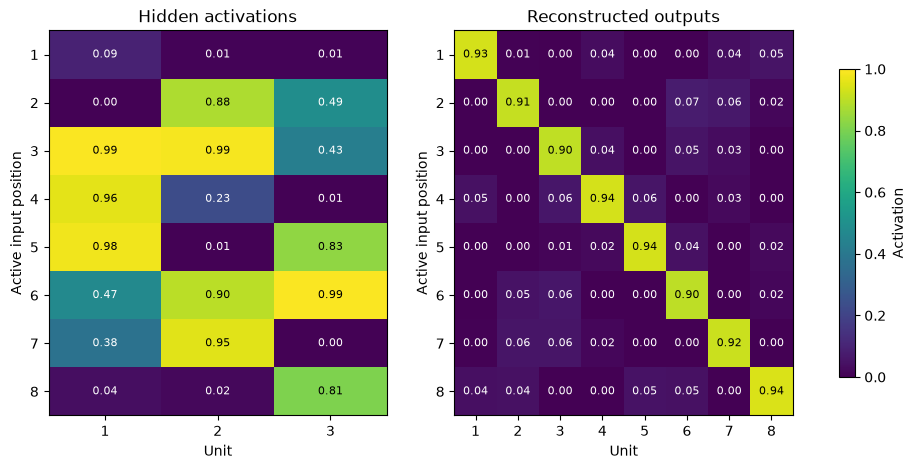

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, values, title in [
    (axes[0], H_trained, "Hidden activations"),
    (axes[1], Y_trained, "Reconstructed outputs"),
]:
    image = ax.imshow(
        values,
        vmin=0,
        vmax=1,
        cmap="viridis",
        aspect="auto",
    )
    ax.set_title(title)
    ax.set_xlabel("Unit")
    ax.set_ylabel("Active input position")
    ax.set_xticks(
        np.arange(values.shape[1]),
        np.arange(1, values.shape[1] + 1),
    )
    ax.set_yticks(np.arange(8), np.arange(1, 9))
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(
                j,
                i,
                f"{values[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="black" if values[i, j] > 0.55 else "white",
            )
fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="Activation",
    shrink=0.8,
)
figure_path = results_directory / "baseline_activations.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

### Interpretation

H1 responds to positions **3, 4, 5**; H2 to **2, 3, 6, 7**; H3 to **5, 6, 8**.

Inputs 2 and 7 share code `010`, but H3 differs (**0.491 vs 0.004**).
Their continuous representations remain distinguishable: eight representations, seven binary codes.

The negative H3 → output 7 weight contributes to suppressing output 7 for input 2.
All incoming weights and the bias jointly determine the output.

In [15]:
baseline_path = results_directory / "baseline_model.npz"

np.savez(
    baseline_path,
    W1=W1_trained,
    b1=b1_trained,
    W2=W2_trained,
    b2=b2_trained,
    hidden_activations=H_trained,
    predicted_outputs=Y_trained,
    loss_history=loss_history,
)

## 12. Conclusion

Manual backpropagation reconstructs all eight training patterns through three hidden units.
Learning rate and initialization affect convergence. Generalization to unseen inputs was not tested.

## References

- *Lab - NN*: task and deliverables.
- *1.1-Linear models*, pp. 26–27, 30: gradient descent.
- *1.2-ANN*, pp. 10, 15–21, 58: forward/backpropagation and random weights.
- *Backprop Help*, Section 2.3: gradient checking.